4.3. GRADIENT BOOSTING REGRESSOR (GBR)
RATIONALE:
1. NON-LINEARITY: Unlike Linear Regression, GBR can capture complex, non-linear relationships.
2. INTERACTION: It automatically learns feature interactions (e.g., Energy vs. Danceability).
3. ROBUSTNESS: It effectively handles the skewed residuals often seen in popularity prediction.

✅ Dataset loaded: 'spotify_prepared_for_models.csv'
Shape: (952, 18)

Feature Definition:
Target Variable: log_streams
Input Features: 17 (Numeric/Encoded)

Train-Test Split:
Training Samples: 761
Test Samples:     191

[Step A] Fitting UNTUNED Gradient Boosting Model (Default Params)...

--- GBR (Untuned) Results ---
RMSE: 0.4830
MAE:  0.3659
R²:   0.7730

[Step B] Running Optimization 1: Coarse Grid Search...
Best Coarse Params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}

--- GBR (Tuned Round 1) Results ---
RMSE: 0.4708
MAE:  0.3600
R²:   0.7843

[Step C] Running Optimization 2: Fine Tuning...
Best Fine Params: {'learning_rate': 0.04500

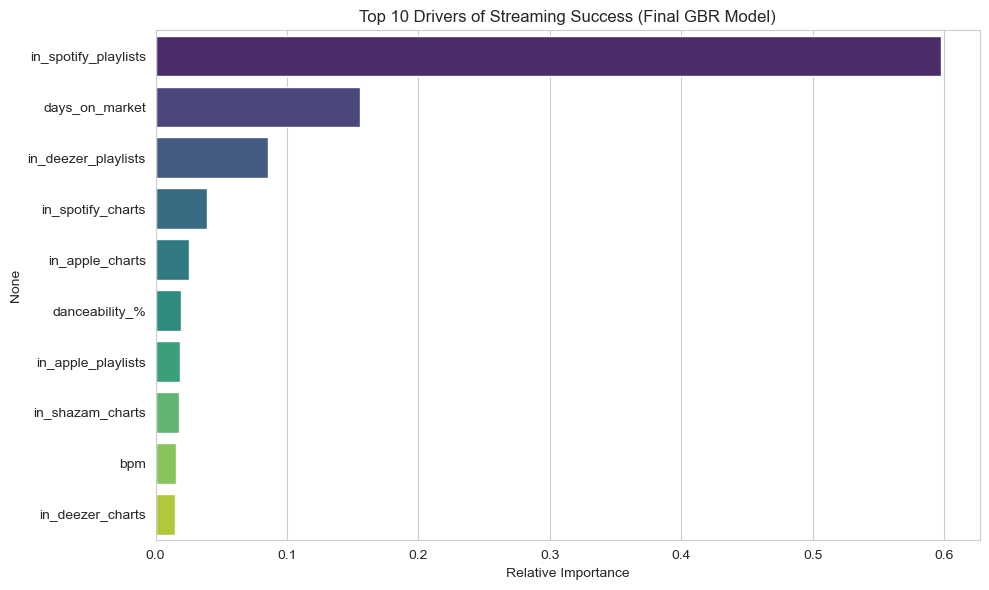

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import warnings

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")

# =============================================================================
# 1. OVERVIEW AND RATIONALE
# =============================================================================
print("="*80)
print("4.3. GRADIENT BOOSTING REGRESSOR (GBR)")
print("="*80)
print("RATIONALE:")
print("1. NON-LINEARITY: Unlike Linear Regression, GBR can capture complex, non-linear relationships.")
print("2. INTERACTION: It automatically learns feature interactions (e.g., Energy vs. Danceability).")
print("3. ROBUSTNESS: It effectively handles the skewed residuals often seen in popularity prediction.")

# =============================================================================
# 2. FEATURE DEFINITION AND TARGET VARIABLE
# =============================================================================
# Load the CLEAN dataset from Part 3
# CRITICAL FIX: Ensure this filename matches what Part 3 saved!
filename = 'spotify_prepared_for_models.csv'

try:
    df = pd.read_csv(filename)
    print(f"\n✅ Dataset loaded: '{filename}'")
    print(f"Shape: {df.shape}")
except FileNotFoundError:
    print(f"\n❌ Error: '{filename}' not found.")
    print("Please go back and run Part 3 to generate this file.")
    df = pd.DataFrame() 

if not df.empty:
    # Define Target and Features
    target = 'log_streams'
    
    # Identify non-numeric columns to drop (Metadata) just in case
    non_numeric = df.select_dtypes(exclude=[np.number]).columns.tolist()
    cols_to_drop = non_numeric + [target, 'streams']
    
    # Define X (Features) and y (Target)
    X = df.drop(columns=[c for c in cols_to_drop if c in df.columns])
    y = df[target]

    print(f"\nFeature Definition:")
    print(f"Target Variable: {target}")
    print(f"Input Features: {X.shape[1]} (Numeric/Encoded)")

    # =============================================================================
    # 3. TRAIN-TEST SPLIT AND PROCESSING PIPELINE
    # =============================================================================
    # Split the data 80% Train / 20% Test
    # Random State 42 ensures this split matches Linear Regression for fair comparison
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    print(f"\nTrain-Test Split:")
    print(f"Training Samples: {X_train.shape[0]}")
    print(f"Test Samples:     {X_test.shape[0]}")

    # Helper function for evaluation
    def evaluate(model, X_test, y_test, label):
        y_pred = model.predict(X_test)
        rmse = np.sqrt(mean_squared_error(y_test, y_pred))
        mae = mean_absolute_error(y_test, y_pred)
        r2 = r2_score(y_test, y_pred)
        print(f"\n--- {label} Results ---")
        print(f"RMSE: {rmse:.4f}")
        print(f"MAE:  {mae:.4f}")
        print(f"R²:   {r2:.4f}")
        return {'Model': label, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

    # =============================================================================
    # 4. MODEL FITTING AND EVALUATION
    # =============================================================================
    
    # -------------------------------------------------------------------------
    # A. UNTUNED MODEL (Default Parameters)
    # -------------------------------------------------------------------------
    print("\n[Step A] Fitting UNTUNED Gradient Boosting Model (Default Params)...")
    
    gbr_untuned = GradientBoostingRegressor(random_state=42)
    gbr_untuned.fit(X_train, y_train)
    
    res_untuned = evaluate(gbr_untuned, X_test, y_test, "GBR (Untuned)")


    # -------------------------------------------------------------------------
    # B. FINE TUNING 1: COARSE GRID SEARCH (Exploration)
    # -------------------------------------------------------------------------
    print("\n[Step B] Running Optimization 1: Coarse Grid Search...")
    
    param_grid_coarse = {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.05, 0.1, 0.2],
        'max_depth': [3, 4, 5]
    }
    
    grid_coarse = GridSearchCV(
        estimator=GradientBoostingRegressor(random_state=42),
        param_grid=param_grid_coarse,
        scoring='r2', 
        cv=3,
        n_jobs=-1,
        verbose=0
    )
    
    grid_coarse.fit(X_train, y_train)
    best_coarse = grid_coarse.best_estimator_
    
    print(f"Best Coarse Params: {grid_coarse.best_params_}")
    res_coarse = evaluate(best_coarse, X_test, y_test, "GBR (Tuned Round 1)")


    # -------------------------------------------------------------------------
    # C. FINE TUNING 2: FINE GRID SEARCH (Refinement)
    # -------------------------------------------------------------------------
    print("\n[Step C] Running Optimization 2: Fine Tuning...")
    
    # Take best params from Coarse search and look closely around them
    bp = grid_coarse.best_params_
    
    param_grid_fine = {
        'n_estimators': [bp['n_estimators'], bp['n_estimators'] + 50],
        'learning_rate': [bp['learning_rate'] * 0.9, bp['learning_rate'], bp['learning_rate'] * 1.1],
        'max_depth': [bp['max_depth']] 
    }
    
    # Add regularization parameter for fine tuning
    param_grid_fine['min_samples_split'] = [2, 5] 
    
    grid_fine = GridSearchCV(
        estimator=GradientBoostingRegressor(random_state=42),
        param_grid=param_grid_fine,
        scoring='r2',
        cv=3,
        n_jobs=-1,
        verbose=0
    )
    
    grid_fine.fit(X_train, y_train)
    best_fine = grid_fine.best_estimator_
    
    print(f"Best Fine Params: {grid_fine.best_params_}")
    res_fine = evaluate(best_fine, X_test, y_test, "GBR (Tuned Round 2)")


    # =============================================================================
    # 5. SUMMARY OF MODEL PERFORMANCE
    # =============================================================================
    print("\n" + "="*80)
    print("SUMMARY OF GBR EVOLUTION")
    print("="*80)
    
    summary_df = pd.DataFrame([res_untuned, res_coarse, res_fine])
    summary_df.set_index('Model', inplace=True)
    
    print(summary_df.round(4).to_markdown())
    
    # Visualizing Feature Importance (Best Model)
    print("\nGenerating Feature Importance Plot...")
    feature_imp = pd.Series(best_fine.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x=feature_imp.values, y=feature_imp.index, palette="viridis")
    plt.title("Top 10 Drivers of Streaming Success (Final GBR Model)")
    plt.xlabel("Relative Importance")
    plt.tight_layout()
    plt.show()

else:
    print("\n⚠️ PROCESS HALTED: No data loaded.")
    print("Ensure 'spotify_prepared_for_models.csv' exists in your directory.")